# Phishing Website Detection Using Machine Learning

## Step 2: Exploratory Data Analysis (EDA)

### Objectives
- Analyze the target variable distribution.
- Explore URL-related features.
- Visualize feature distributions and relationships.
- Identify patterns that may help distinguish phishing URLs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/phishing_dataset.csv")

print("Dataset shape:", df.shape)

Dataset shape: (39676, 17)


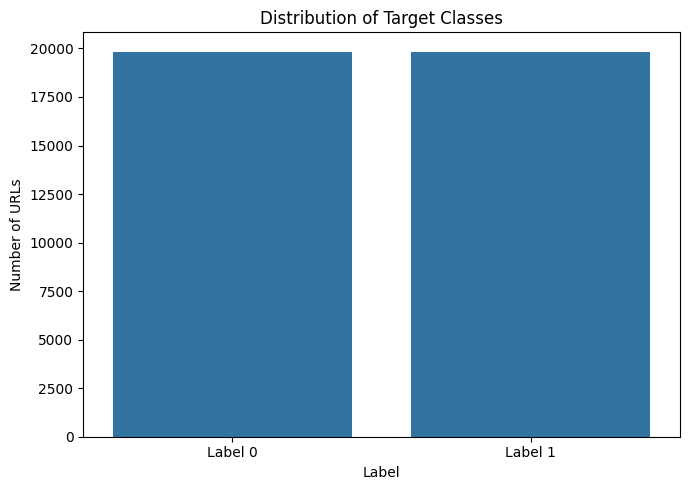

In [2]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("Distribution of Target Classes")
plt.xlabel("Label")
plt.ylabel("Number of URLs")
plt.xticks([0, 1], ["Label 0", "Label 1"])

plt.tight_layout()
plt.show()

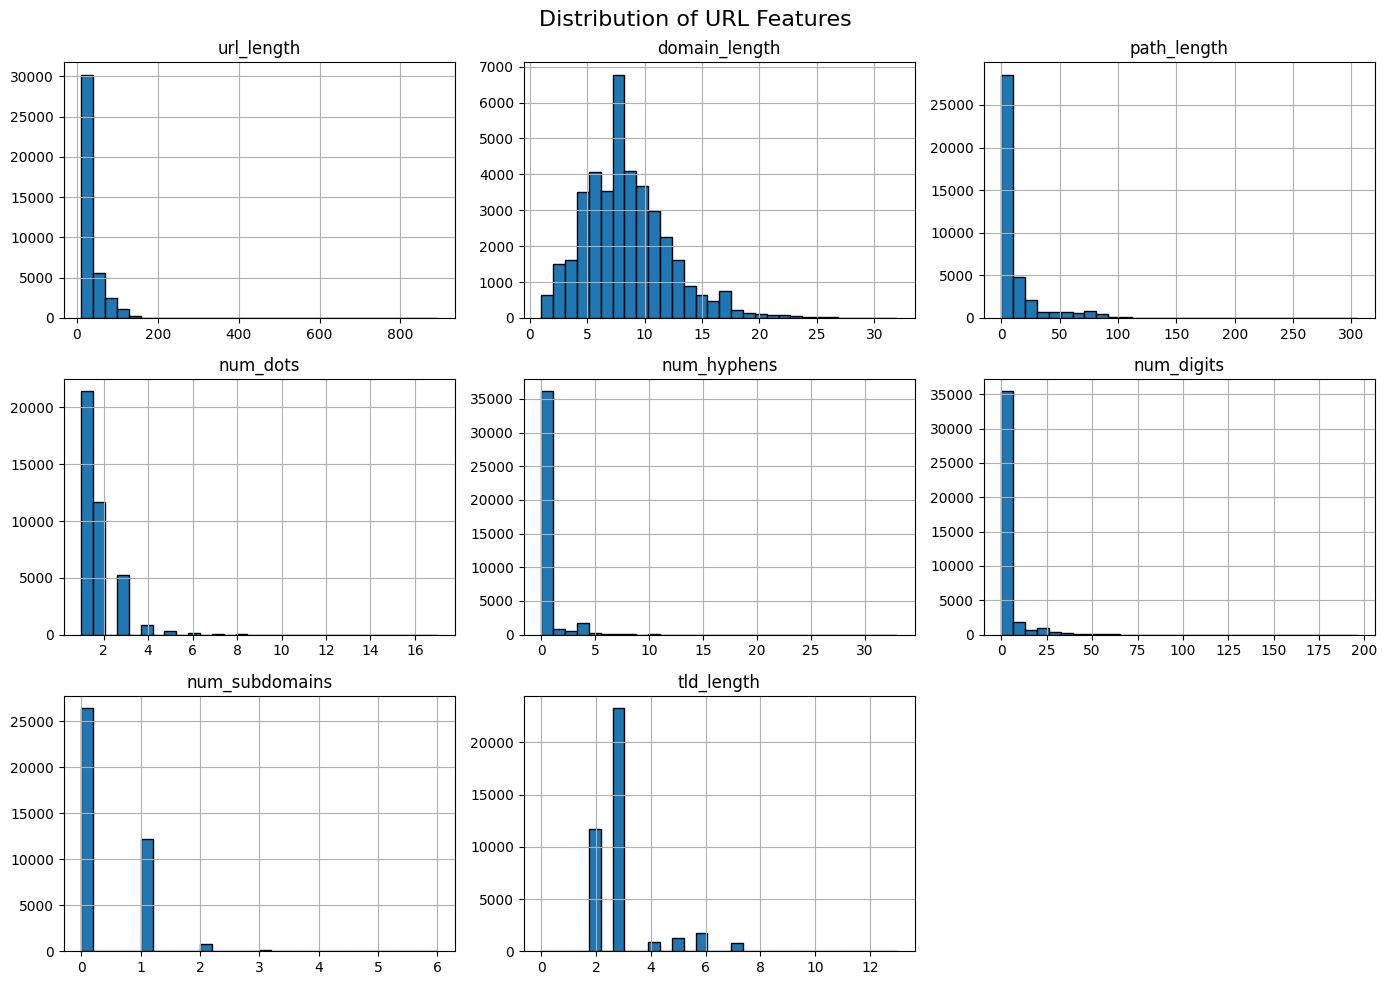

In [3]:
features = [
    "url_length",
    "domain_length",
    "path_length",
    "num_dots",
    "num_hyphens",
    "num_digits",
    "num_subdomains",
    "tld_length"
]

df[features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of URL Features", fontsize=16)
plt.tight_layout()
plt.show()

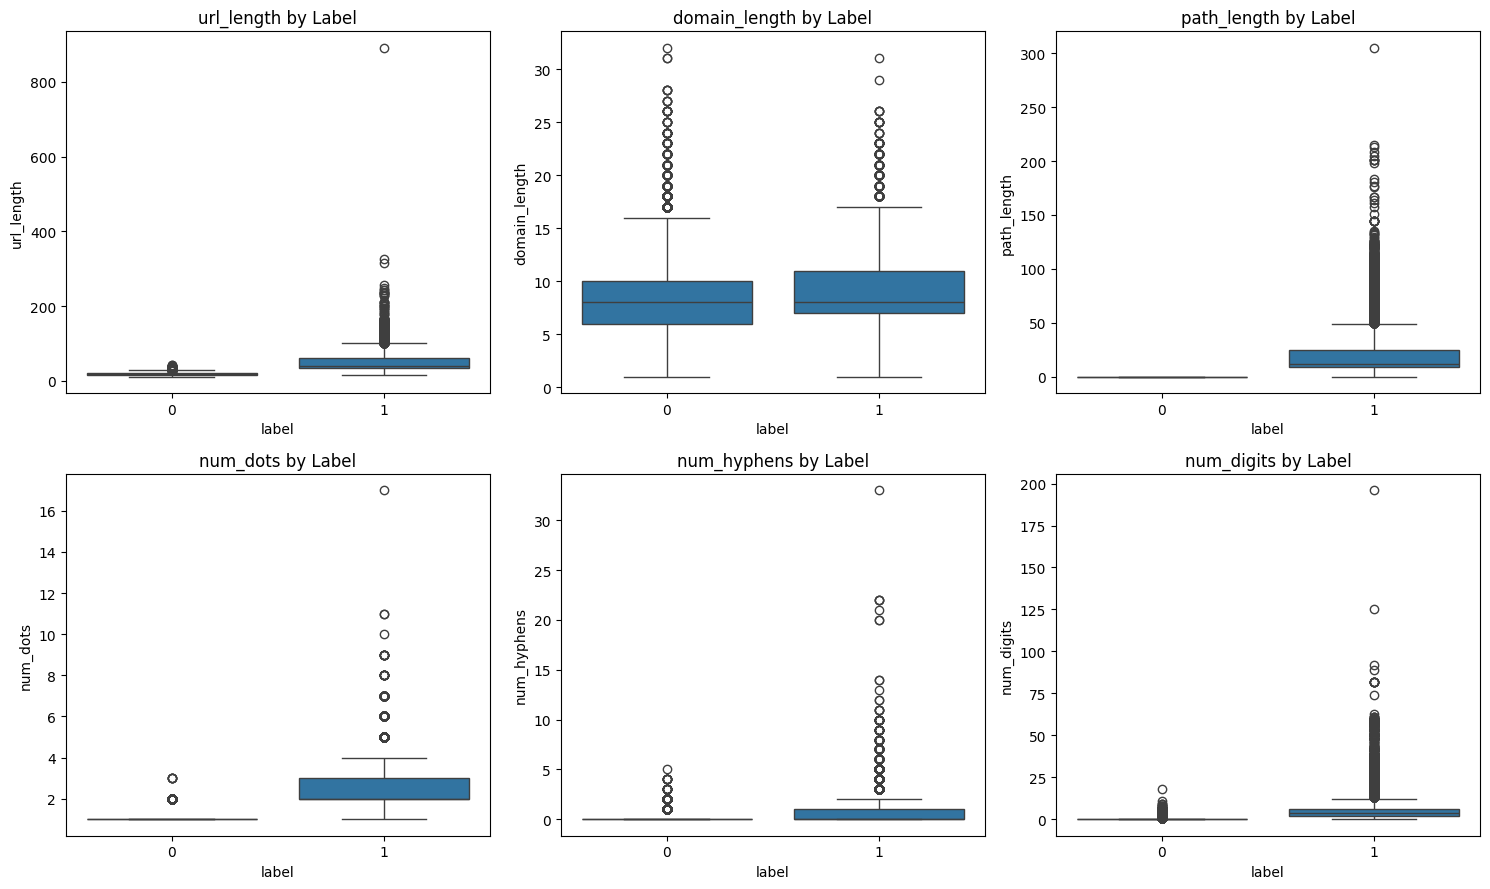

In [4]:
features_to_compare = [
    "url_length",
    "domain_length",
    "path_length",
    "num_dots",
    "num_hyphens",
    "num_digits"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for feature, ax in zip(features_to_compare, axes.flatten()):
    sns.boxplot(
        data=df,
        x="label",
        y=feature,
        ax=ax
    )
    ax.set_title(f"{feature} by Label")

plt.tight_layout()
plt.show()

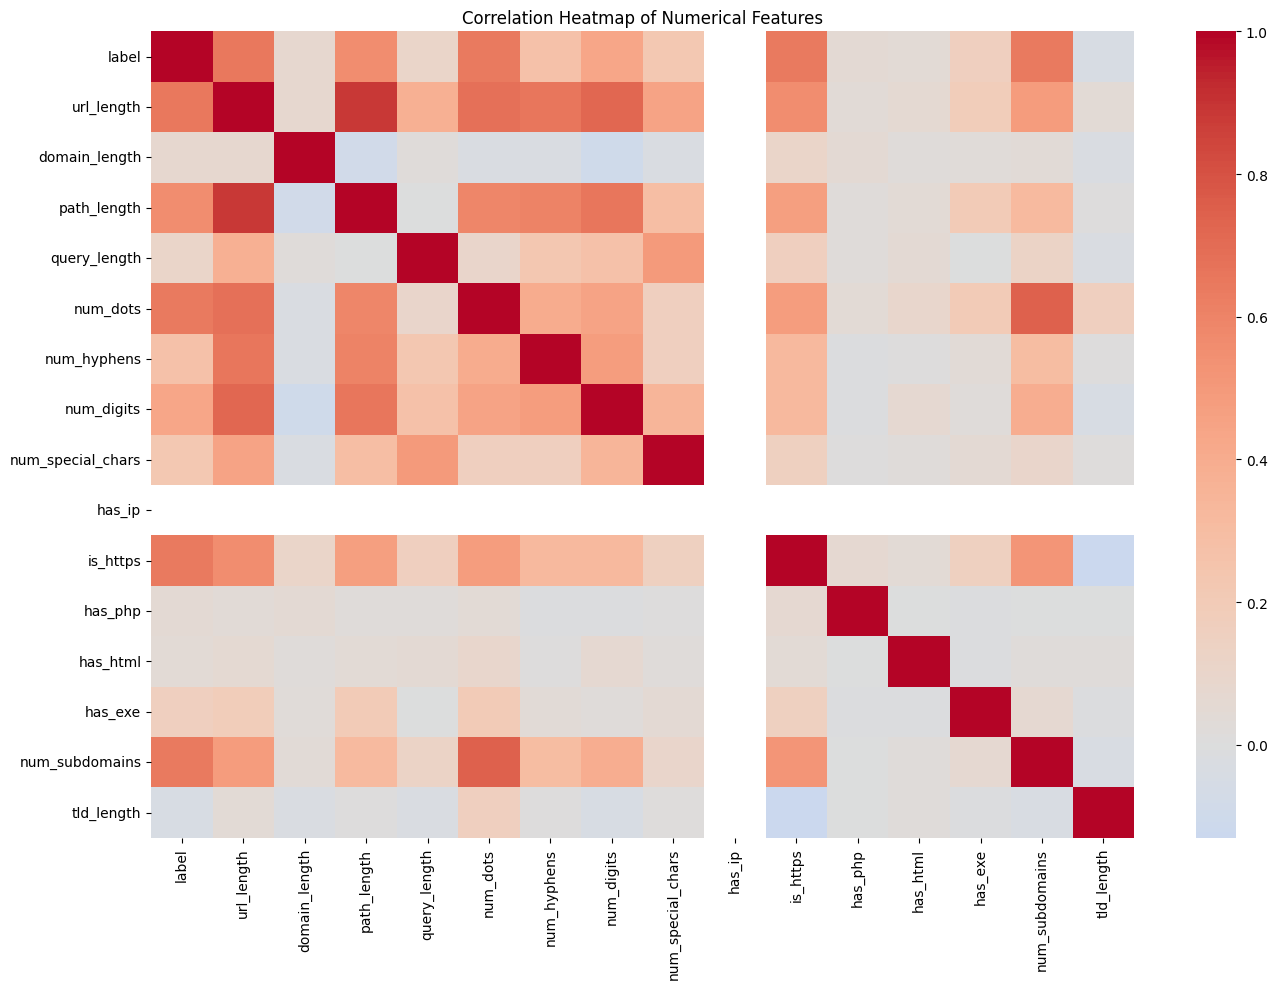

In [5]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

## EDA Findings

1. **Target distribution:** The dataset contains 19,838 records for each class, giving a balanced distribution of 50% per class.
2. **Feature distributions:** Several URL-related numerical features are right-skewed, with most values concentrated at the lower end and a smaller number of large values.
3. **Potential outliers:** Box plots reveal extreme observations in features such as URL length, path length, number of dots, hyphens and digits. These observations require investigation rather than automatic removal.
4. **Feature relationships:** The correlation heatmap suggests positive relationships between some URL-related features, particularly URL length and path length.
5. **Further investigation:** The `has_ip` feature appears to have undefined correlations in the heatmap. Its distribution and variance should be checked during preprocessing.

These findings will guide the next stage of data preparation and model development.